# Predicting Online Purchase Intention
## Data understanding, EDA, feature engineering, and train/test preparation

**Research question.** Can machine learning predict whether an online shopping session will result in a purchase, and which customer browsing behaviors are most predictive of conversion?

**Business objective.** Help e-commerce teams identify sessions with high purchase intent and prioritize targeting and marketing decisions.

This notebook completes the three requested preparation tasks. It does not train or evaluate a predictive model. EDA shows associations; model comparisons and held-out performance are required before claiming predictive success or ranking model importance.

**Problem framing:** supervised binary classification with `Revenue` as the target (`1 = purchase`, `0 = no purchase`). Training is offline. The supplied rows describe whole sessions, so results support a retrospective session-level proof of concept. Real-time targeting requires event snapshots captured before purchase and verified feature availability.

**Evaluation plan for the later modeling phase:** use average precision (AP) as the main selection metric because purchases are uncommon. Report ROC-AUC, precision, recall, F1, and precision/lift at a prespecified targeting budget (for example, the top 10% of scored sessions). Tune thresholds using training-only cross-validation and campaign costs; report final performance once on the held-out test set. Accuracy alone rewards predicting no purchase.

**Inputs:** uploaded `online_shoppers_intention.csv` and the INSY 674 Final Project Rubric (Fall 2026). The rubric asks for attribute profiling, labeled plots with written takeaways, correlations, justified transformations, and a leak-free train/test pipeline.

In [1]:
from pathlib import Path
import json
import hashlib
import sys
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn
import joblib
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Run from this project folder, or place the CSV next to the notebook.
BASE = Path.cwd()
if not (BASE / 'session_preprocessing.py').exists():
    raise FileNotFoundError('Open the notebook from the extracted project folder.')
sys.path.insert(0, str(BASE))
from session_preprocessing import (
    SessionFeatureEngineer, make_preprocessing_pipeline,
    COUNT_COLUMNS, DURATION_COLUMNS, NOMINAL_COLUMNS,
    BASE_LOG_COLUMNS, ENGINEERED_LOG_COLUMNS, BOUNDED_COLUMNS, BINARY_COLUMNS, MONTH_ORDER,
)

DATA_PATH = BASE / 'data/raw/online_shoppers_intention.csv'
FIG = BASE / 'figures'
TABLE = BASE / 'tables'
PROCESSED = BASE / 'data/processed'
for folder in [FIG, TABLE, PROCESSED, BASE / 'artifacts']:
    folder.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
COLORS = ['#425870', '#087e8b']
sns.set_theme(style='whitegrid', context='notebook', palette=COLORS)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':180, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.family':'DejaVu Sans'})
pd.set_option('display.max_columns', 20)

def show_figure(fig, filename):
    fig.savefig(FIG / filename, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)

def save_table(frame, name):
    frame.to_csv(TABLE / name, index=False)
    return frame

versions = {name: version for name, version in [
    ('Python', platform.python_version()), ('numpy', np.__version__), ('pandas', pd.__version__),
    ('scipy', scipy.__version__), ('scikit-learn', sklearn.__version__),
    ('matplotlib', __import__('matplotlib').__version__), ('seaborn', sns.__version__),
    ('joblib', joblib.__version__)]}
print(json.dumps(versions, indent=2))

{
  "Python": "3.12.14",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "scikit-learn": "1.8.0",
  "matplotlib": "3.10.8",
  "seaborn": "0.13.2",
  "joblib": "1.5.3"
}


## 1. Data understanding and quality checks

### 1.1 Inventory and measurement definitions
One row is a session. Page-type counts and durations describe administrative, informational, and product-related browsing. `BounceRates`, `ExitRates`, and `PageValues` summarize Google Analytics page metrics. Numeric OS, browser, region, and traffic codes are **nominal categories**. `Revenue` is a purchase indicator, not a revenue amount.

The UCI documentation describes each sampled session as belonging to a different user within one year. The CSV has no user ID, session ID, exact date, or event timestamps, so this sampling claim and feature timing cannot be verified from the file. Month alone is insufficient for a proper prospective time split. Durations are reported in source units because the UCI variable table does not specify their units.

In [2]:
raw = pd.read_csv(DATA_PATH)
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
expected_columns = COUNT_COLUMNS + DURATION_COLUMNS + [
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
    'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']
assert set(raw.columns) == set(expected_columns)
assert raw['Revenue'].dtype == bool and raw['Weekend'].dtype == bool
assert raw['Revenue'].nunique() == 2

numeric_original = ['Administrative','Administrative_Duration','Informational',
                    'Informational_Duration','ProductRelated','ProductRelated_Duration',
                    'BounceRates','ExitRates','PageValues','SpecialDay']
numeric_values = raw.select_dtypes(include='number')
quality = pd.DataFrame([
    ['Rows', len(raw), 'One session per record'],
    ['Input features', raw.shape[1]-1, 'Revenue is the separate target'],
    ['Missing cells', int(raw.isna().sum().sum()), 'No missing-value filling needed for this file'],
    ['Infinite numeric cells', int(np.isinf(numeric_values).sum().sum()), 'Expected: 0'],
    ['Negative numeric cells', int((numeric_values < 0).sum().sum()), 'Counts, durations and rates should be nonnegative'],
    ['Rates outside [0,1]', int((~raw[['BounceRates','ExitRates','SpecialDay']].ge(0) | ~raw[['BounceRates','ExitRates','SpecialDay']].le(1)).sum().sum()), 'Observed BounceRates/ExitRates maxima are 0.2, not a universal domain bound'],
    ['Fractional page counts', int((raw[COUNT_COLUMNS] % 1 != 0).sum().sum()), 'Counts should be whole numbers'],
    ['Exact duplicate rows beyond first', int(raw.duplicated().sum()), 'Candidate repeated records; identity cannot be verified'],
    ['Zero tracked-page sessions', int(raw[COUNT_COLUMNS].sum(axis=1).eq(0).sum()), 'Keep and flag'],
    ['Months represented', raw['Month'].nunique(), 'January and April are absent; no rows are invented'],
    ['Purchase sessions', int(raw['Revenue'].sum()), 'Positive class'],
    ['Purchase rate (%)', round(raw['Revenue'].mean()*100,4), 'Imbalanced target'],
], columns=['check','value','interpretation'])
display(save_table(quality, '01_data_quality.csv'))
display(raw.head())
print('SHA-256:', source_hash)

duration_audit = pd.DataFrame([
    {'page_type': c,
     'zero_pages_positive_duration': int(((raw[c]==0)&(raw[c+'_Duration']>0)).sum()),
     'positive_pages_zero_duration': int(((raw[c]>0)&(raw[c+'_Duration']==0)).sum())}
    for c in COUNT_COLUMNS])
display(save_table(duration_audit, '02_duration_audit.csv'))

,check,value,interpretation
0,Rows,12330.0000,One session per record
1,Input features,17.0000,Revenue is the separate target
2,Missing cells,0.0000,No missing-value filling needed for this file
3,Infinite numeric cells,0.0000,Expected: 0
4,Negative numeric cells,0.0000,"Counts, durations and rates should be nonnegative"
5,"Rates outside [0,1]",0.0000,"Observed BounceRates/ExitRates maxima are 0.2, not a universal domain bound"
6,Fractional page counts,0.0000,Counts should be whole numbers
7,Exact duplicate rows beyond first,125.0000,Candidate repeated records; identity cannot be verified
8,Zero tracked-page sessions,6.0000,Keep and flag
9,Months represented,10.0000,January and April are absent; no rows are invented


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,page_type,zero_pages_positive_duration,positive_pages_zero_duration
0,Administrative,0,135
1,Informational,0,226
2,ProductRelated,0,717


SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


**Quality decisions.** There are 12,330 sessions, 17 inputs, zero missing values, and 125 exact duplicate rows beyond their first occurrence. All 125 repeated rows have `Revenue=False`. Nonnegative-value and logical-bound checks pass. Positive page counts sometimes have zero recorded duration, which can reflect analytics measurement rather than invalid browsing. These records and the six zero-tracked-page sessions are retained. No outliers are deleted merely because they are extreme.

**Duplicate assumption.** Without identifiers, identical observations could be independent sessions. For this coursework baseline, exact full-row duplicates are removed conservatively before splitting to prevent repeated vectors crossing partitions. This changes the estimand to the retained distinct records and slightly changes the conversion rate. The original CSV and the removed rows are preserved for a later duplicate-group sensitivity analysis. Duplicate removal is a documented assumption, not proof that those rows were erroneous.

### 1.2 Protect the test set before exploratory decisions
The train/test split is performed here, before target-guided EDA, feature comparisons, imputation, encoding, or scaling. Its implementation is discussed again in Section 3. Full-file inventory and deterministic quality checks above are the only pre-split summaries.

In [3]:
# source_row_id is the 0-based data-row number in the original CSV, excluding its header.
# It is an audit/join key, never a model input.
is_duplicate = raw.duplicated(keep='first')
removed_duplicates = raw.loc[is_duplicate].copy()
removed_duplicates.insert(0, 'source_row_id', removed_duplicates.index)
removed_duplicates.to_csv(PROCESSED / 'removed_exact_duplicates.csv', index=False)

clean = raw.loc[~is_duplicate].copy()
clean.index.name = 'source_row_id'
clean['Revenue'] = clean['Revenue'].astype(int)
X = clean.drop(columns='Revenue')
y = clean['Revenue']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
train = X_train.join(y_train)

# Dataset integrity: no row overlap, no exact model-input vector shared between splits.
assert set(X_train.index).isdisjoint(set(X_test.index))
train_signatures = pd.util.hash_pandas_object(X_train.drop(columns='PageValues'), index=False)
test_signatures = pd.util.hash_pandas_object(X_test.drop(columns='PageValues'), index=False)
assert set(train_signatures).isdisjoint(set(test_signatures))
assert len(X_train) + len(X_test) == len(clean)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert y_train.nunique() == y_test.nunique() == 2

split_summary = pd.DataFrame([
    {'partition':name, 'sessions':len(labels), 'no_purchase':int(labels.eq(0).sum()),
     'purchase':int(labels.eq(1).sum()), 'purchase_rate_pct':labels.mean()*100}
    for name, labels in [('Raw inventory', raw.Revenue.astype(int)),
                          ('After exact deduplication', y), ('Training', y_train), ('Test', y_test)]])
display(save_table(split_summary, '03_split_summary.csv').round(4))
# Only split size, label stratification and schema/integrity are inspected for test rows.

,partition,sessions,no_purchase,purchase,purchase_rate_pct
0,Raw inventory,12330,10422,1908,15.4745
1,After exact deduplication,12205,10297,1908,15.6329
2,Training,9764,8238,1526,15.6288
3,Test,2441,2059,382,15.6493


### 1.3 Profile every attribute
The dictionary records meaning, storage dtype, modeling role, missingness, training distribution, measurement concerns, usefulness, and planned preparation. Raw-file missingness is reported for completeness; all distribution statistics and association analyses below use **training rows only**.

In [4]:
definitions = {
 'Administrative': ('Administrative page count','Right-skewed count, many zeros','May reflect account/checkout-related navigation; URLs are not supplied','log1p + standardize'),
 'Administrative_Duration': ('Time on administrative pages','Right-skewed, zero-inflated','Engagement depth; high tails and zero-duration measurement require care','log1p + standardize'),
 'Informational': ('Informational page count','Right-skewed, strongly zero-inflated','Research-oriented browsing; zero means no recorded page of this type','log1p + standardize'),
 'Informational_Duration': ('Time on informational pages','Right-skewed, strongly zero-inflated','Research depth; positive counts can have zero recorded duration','log1p + standardize'),
 'ProductRelated': ('Product-related page count','Right-skewed count','Direct browsing-depth candidate; unusually large sessions may be genuine or automated','log1p + standardize'),
 'ProductRelated_Duration': ('Time on product-related pages','Right-skewed, long upper tail','Product engagement candidate; no verified duration units','log1p + standardize'),
 'BounceRates': ('Page bounce-rate metric associated with session','Bounded [0,1], zero-heavy','Abandonment association; verify that page-level statistics predate prediction','Median impute + standardize; no log'),
 'ExitRates': ('Page exit-rate metric associated with session','Bounded [0,1], right-skewed','Exit tendency candidate; timing of page-level statistics needs verification','Median impute + standardize; no log'),
 'PageValues': ('Analytics value of visited pages associated with transactions','Nonnegative, zero-inflated, right-skewed','Outcome-related calculation may use information unavailable before purchase','Audit only; exclude from default pipeline'),
 'SpecialDay': ('Closeness to a special shopping day','Bounded [0,1], discrete score, many zeros','Calendar context; this is not a distance measured in days','Median impute + standardize; no log'),
 'Month': ('Session month','Nominal calendar category; 10 of 12 months observed','Seasonal context; one year cannot establish stable seasonality','One-hot encode; no fabricated months'),
 'OperatingSystems': ('Operating-system category code','Nominal integer code','Technical context; numbers have no ranking','String labels + one-hot encode'),
 'Browser': ('Browser category code','Nominal integer code, some rare levels','Technical context; sparse levels have uncertain conversion rates','String labels + one-hot encode; unknowns ignored'),
 'Region': ('Geographic region category code','Nominal integer code','Geographic context; no lookup table for real location names','String labels + one-hot encode'),
 'TrafficType': ('Traffic-source category code','Nominal integer code, some rare levels','Acquisition context; IDs do not identify named channels','String labels + one-hot encode; unknowns ignored'),
 'VisitorType': ('New, returning, or other visitor','Nominal category, returning visitors dominate','Customer-history proxy; Other has few observations','One-hot encode'),
 'Weekend': ('Whether the session occurred on a weekend','Binary flag','Calendar context, lower-dimensional than day of week','0/1, no scaling'),
 'Revenue': ('Whether a purchase occurred','Binary target, minority positive class','Observed conversion outcome, not revenue amount','0/1 target only; never an input'),
}
profile_rows=[]
for col in raw.columns:
    s=train[col]
    meaning, distribution, usefulness, treatment=definitions[col]
    is_num = col in numeric_original
    q1,q3 = (s.quantile(.25),s.quantile(.75)) if is_num else (np.nan,np.nan)
    iqr=q3-q1
    profile_rows.append({
        'feature':col, 'meaning':meaning, 'storage_dtype':str(raw[col].dtype),
        'model_role':('target' if col=='Revenue' else 'numeric' if is_num else 'binary' if col=='Weekend' else 'nominal'),
        'missing_pct_raw':raw[col].isna().mean()*100,
        'unique_train':s.nunique(), 'min_train':s.min() if is_num else np.nan,
        'median_train':s.median() if is_num else np.nan, 'max_train':s.max() if is_num else np.nan,
        'zero_pct_train':s.eq(0).mean()*100 if is_num else np.nan,
        'skew_train':s.skew() if is_num else np.nan,
        'iqr_flag_pct_train':((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).mean()*100 if is_num else np.nan,
        'distribution':distribution, 'usefulness_and_noise':usefulness, 'preparation':treatment,
    })
attribute_profile=pd.DataFrame(profile_rows)
display(save_table(attribute_profile, '04_attribute_profile.csv').round(4))
display(save_table(train[numeric_original].describe(percentiles=[.25,.5,.75,.95,.99]).T.reset_index(names='feature'),
                   '05_numeric_summary_train.csv').round(4))

,feature,meaning,storage_dtype,model_role,missing_pct_raw,unique_train,min_train,median_train,max_train,zero_pct_train,skew_train,iqr_flag_pct_train,distribution,usefulness_and_noise,preparation
0,Administrative,Administrative page count,int64,numeric,0.0,27,0.0,1.0000,27.0000,46.2515,1.9861,3.3286,"Right-skewed count, many zeros",May reflect account/checkout-related navigation; URLs are not supplied,log1p + standardize
1,Administrative_Duration,Time on administrative pages,float64,numeric,0.0,2801,0.0,9.0000,3398.7500,47.3679,5.6769,9.5965,"Right-skewed, zero-inflated",Engagement depth; high tails and zero-duration measurement require care,log1p + standardize
2,Informational,Informational page count,int64,numeric,0.0,17,0.0,0.0000,24.0000,78.4207,4.0987,21.5793,"Right-skewed, strongly zero-inflated",Research-oriented browsing; zero means no recorded page of this type,log1p + standardize
3,Informational_Duration,Time on informational pages,float64,numeric,0.0,1058,0.0,0.0000,2549.3750,80.3667,7.5427,19.6333,"Right-skewed, strongly zero-inflated",Research depth; positive counts can have zero recorded duration,log1p + standardize
4,ProductRelated,Product-related page count,int64,numeric,0.0,289,0.0,18.0000,705.0000,0.3277,4.3898,7.8554,Right-skewed count,Direct browsing-depth candidate; unusually large sessions may be genuine or automated,log1p + standardize
5,ProductRelated_Duration,Time on product-related pages,float64,numeric,0.0,7791,0.0,617.0000,63973.5222,5.1516,7.8719,7.6915,"Right-skewed, long upper tail",Product engagement candidate; no verified duration units,log1p + standardize
6,BounceRates,Page bounce-rate metric associated with session,float64,numeric,0.0,1585,0.0,0.0029,0.2000,45.3195,3.1730,11.5424,"Bounded [0,1], zero-heavy",Abandonment association; verify that page-level statistics predate prediction,Median impute + standardize; no log
7,ExitRates,Page exit-rate metric associated with session,float64,numeric,0.0,3984,0.0,0.0250,0.2000,0.6555,2.2369,7.9885,"Bounded [0,1], right-skewed",Exit tendency candidate; timing of page-level statistics needs verification,Median impute + standardize; no log
8,PageValues,Analytics value of visited pages associated with transactions,float64,numeric,0.0,2174,0.0,0.0000,361.7637,77.6014,6.5473,22.3986,"Nonnegative, zero-inflated, right-skewed",Outcome-related calculation may use information unavailable before purchase,Audit only; exclude from default pipeline
9,SpecialDay,Closeness to a special shopping day,float64,numeric,0.0,6,0.0,0.0000,1.0000,89.6764,3.2690,10.3236,"Bounded [0,1], discrete score, many zeros",Calendar context; this is not a distance measured in days,Median impute + standardize; no log


,feature,count,mean,std,min,25%,50%,75%,95%,99%,max
0,Administrative,9764.0,2.3427,3.3493,0.0,0.0000,1.0000,4.0000,9.0000,14.0000,27.0000
1,Administrative_Duration,9764.0,82.2199,179.5024,0.0,0.0000,9.0000,94.7250,353.6700,845.5329,3398.7500
2,Informational,9764.0,0.5103,1.2827,0.0,0.0000,0.0000,0.0000,3.0000,6.0000,24.0000
3,Informational_Duration,9764.0,34.9506,143.8283,0.0,0.0000,0.0000,0.0000,193.2125,746.8450,2549.3750
4,ProductRelated,9764.0,32.1018,44.8173,0.0,8.0000,18.0000,39.0000,109.8500,221.0000,705.0000
5,ProductRelated_Duration,9764.0,1207.2647,1926.3892,0.0,193.4667,617.0000,1483.6500,4306.2755,8690.3201,63973.5222
6,BounceRates,9764.0,0.0203,0.0452,0.0,0.0000,0.0029,0.0167,0.1500,0.2000,0.2000
7,ExitRates,9764.0,0.0415,0.0461,0.0,0.0143,0.0250,0.0492,0.1750,0.2000,0.2000
8,PageValues,9764.0,5.9456,18.8601,0.0,0.0000,0.0000,0.0000,38.1149,86.6566,361.7637
9,SpecialDay,9764.0,0.0624,0.2000,0.0,0.0000,0.0000,0.0000,0.6000,1.0000,1.0000


**Distribution takeaway.** Counts, durations, and `PageValues` have long right tails and many zeros. A large IQR-flag share is not proof of bad data, particularly when the IQR is zero. Preserve valid sessions, use `log1p` on counts/durations/average times, and standardize using training statistics. Rates remain on their original scale before standardization. Numeric category IDs are excluded from numeric correlations.

### 1.4 Feature visualizations and purchase associations
Every chart identifies its population. The panels cover all original inputs, including coded categories. Whiskers on conversion-rate plots are 95% Wilson intervals for descriptive binomial uncertainty; they are not causal effects or multiple-comparison-adjusted significance tests.

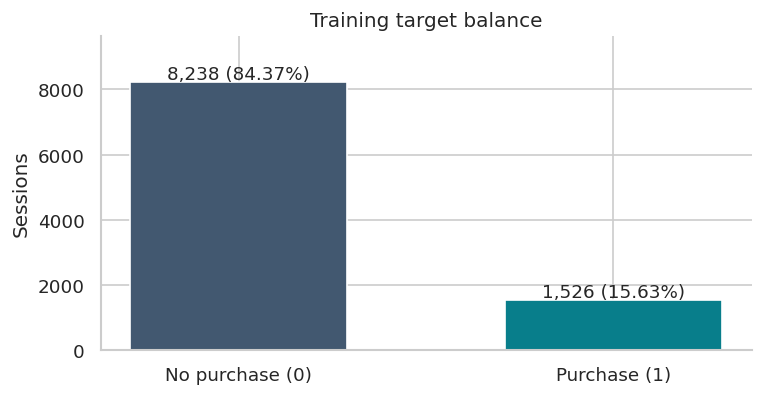

Majority-class accuracy baseline (training): 84.37%
Random-ranking expected AP baseline (training prevalence): 15.63%


In [5]:
fig,ax=plt.subplots(figsize=(7,3.4))
counts=y_train.value_counts().sort_index()
bars=ax.bar(['No purchase (0)','Purchase (1)'], counts, color=COLORS, width=.58)
for bar,n in zip(bars,counts):
    ax.text(bar.get_x()+bar.get_width()/2,n+90,f'{n:,} ({n/len(y_train):.2%})',ha='center',fontsize=11)
ax.set(title='Training target balance',ylabel='Sessions',ylim=(0,counts.max()*1.17))
show_figure(fig,'01_training_target_balance.png')
print(f'Majority-class accuracy baseline (training): {1-y_train.mean():.2%}')
print(f'Random-ranking expected AP baseline (training prevalence): {y_train.mean():.2%}')

**Takeaway.** The retained training records have a 15.63% purchase rate. Predicting no purchase for every session would achieve 84.37% accuracy while finding no buyers. Preserve class proportions in the split and use AP plus business targeting measures in the later modeling phase. No oversampling is applied before the split.

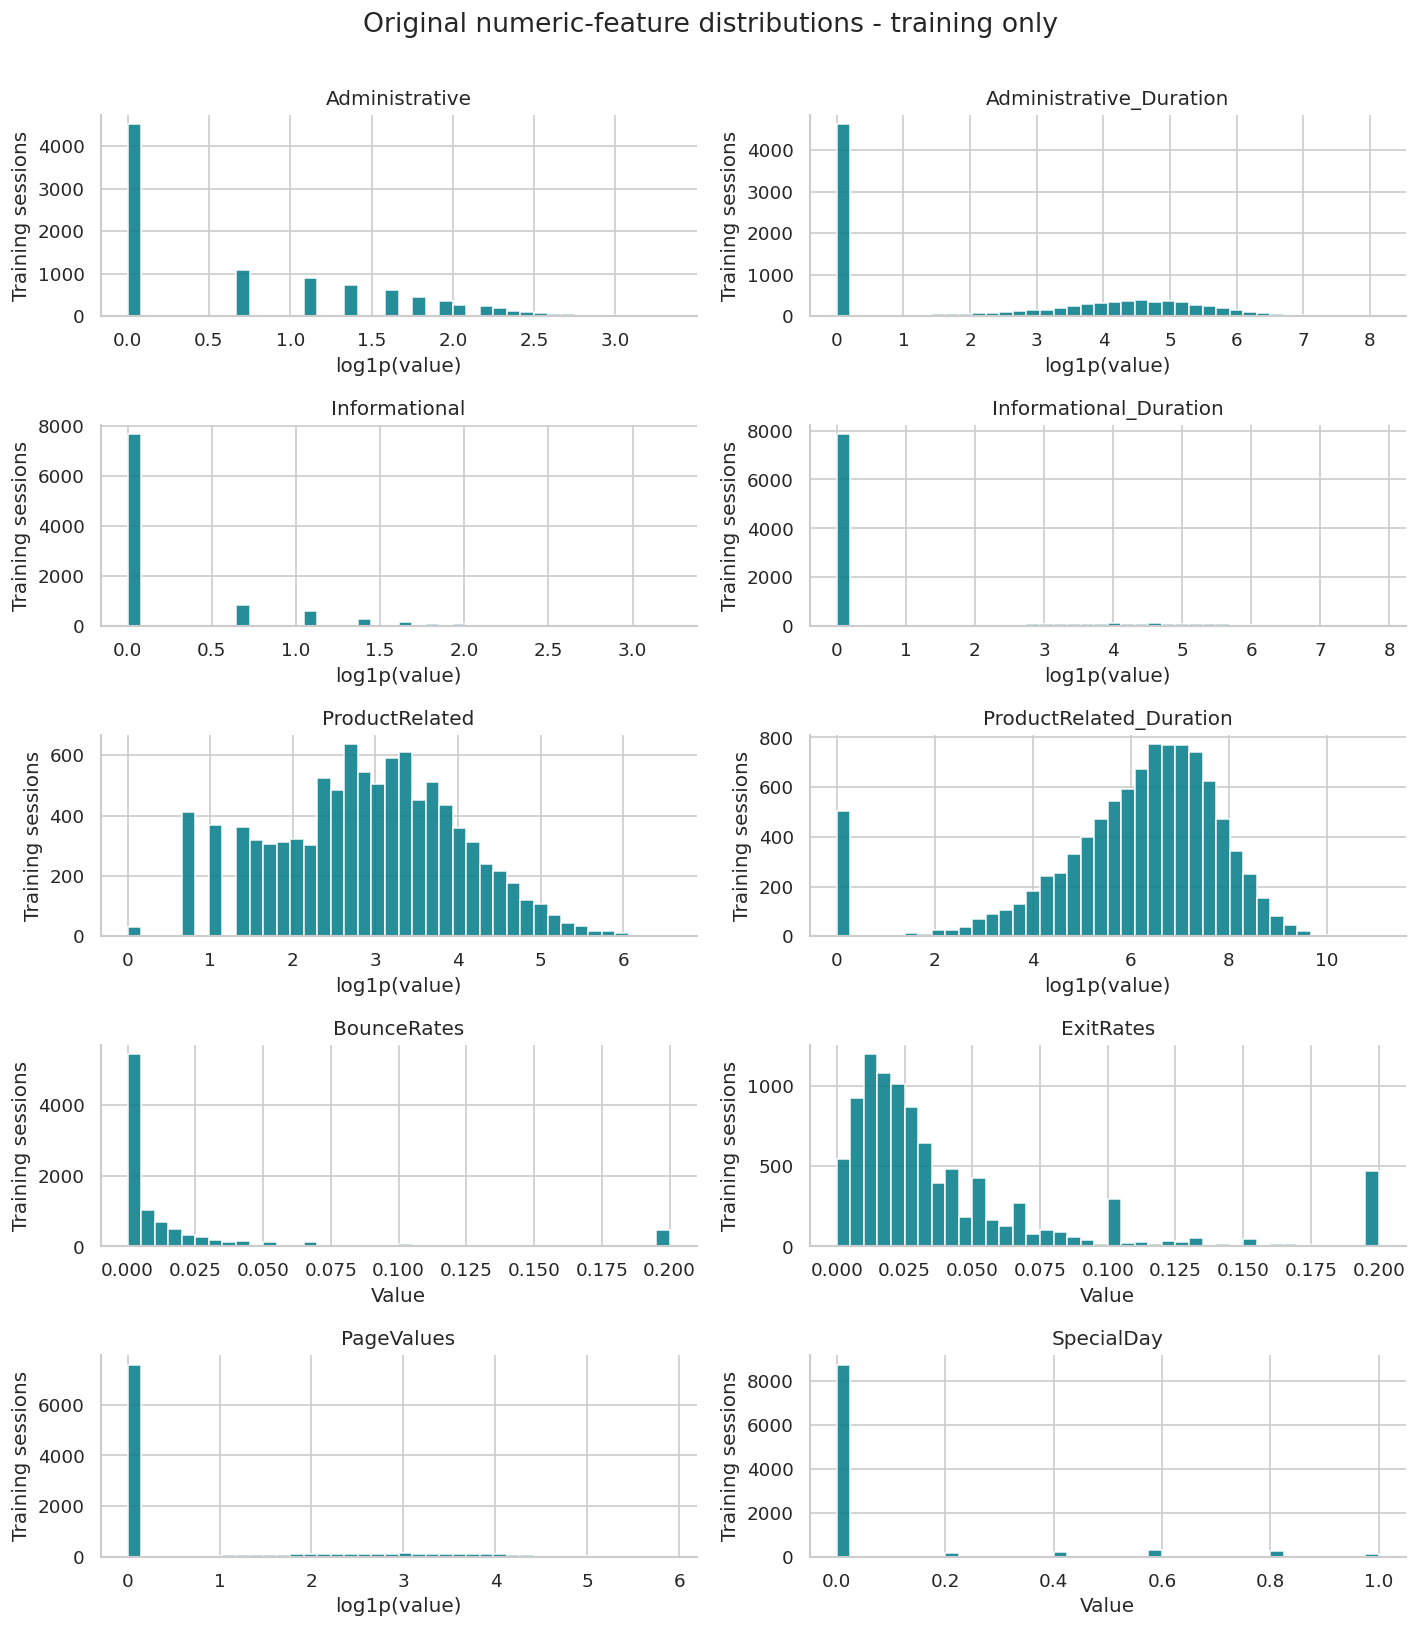

In [6]:
fig,axes=plt.subplots(5,2,figsize=(12,13.5))
logged=set(BASE_LOG_COLUMNS+['PageValues'])
for ax,col in zip(axes.flat,numeric_original):
    values=np.log1p(train[col]) if col in logged else train[col]
    ax.hist(values,bins=40,color='#087e8b',alpha=.88)
    ax.set(title=col,xlabel='log1p(value)' if col in logged else 'Value',ylabel='Training sessions')
fig.suptitle('Original numeric-feature distributions - training only',fontsize=16,y=1.005)
fig.tight_layout()
show_figure(fig,'02_numeric_distributions_train.png')

**Takeaway.** Product browsing spans a much wider range than a normal distribution would suggest. Administrative and informational measures contain many zeros. Log transforms compress the long tails while preserving zero and rank order. `PageValues` is plotted for transparency but is excluded from default modeling inputs.

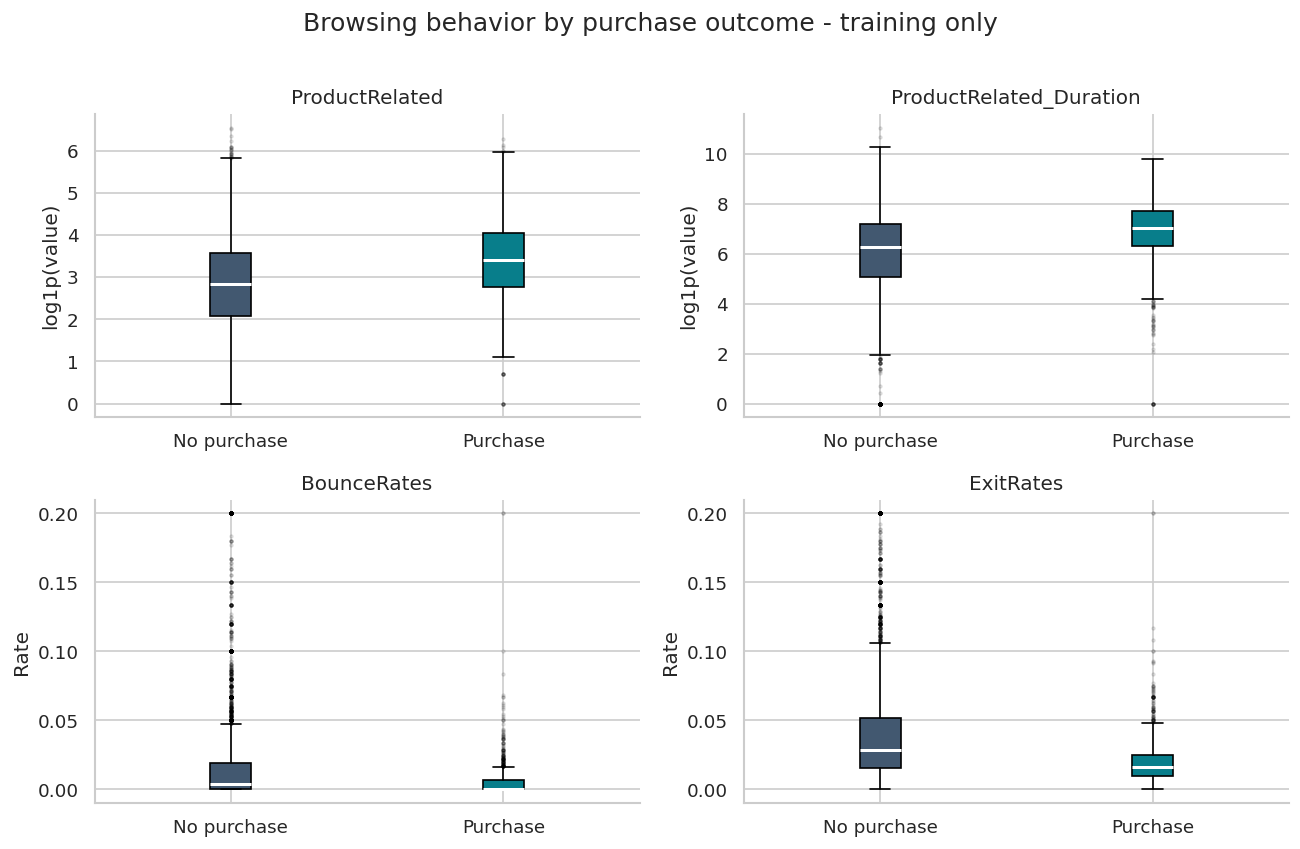

,feature,no_purchase_median,purchase_median
0,ProductRelated,16.00000,29.00000
1,ProductRelated_Duration,530.81250,1122.91500
2,BounceRates,0.00377,0.00000
3,ExitRates,0.02846,0.01629
4,PageValues,0.00000,16.35920


In [7]:
comparison_features=['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates']
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axes.flat,comparison_features):
    vals=[train.loc[train.Revenue.eq(label),col] for label in [0,1]]
    if col in ['ProductRelated','ProductRelated_Duration']:
        vals=[np.log1p(v) for v in vals]
    bp=ax.boxplot(vals,tick_labels=['No purchase','Purchase'],patch_artist=True,
                  flierprops={'markersize':1.5,'alpha':.15},medianprops={'color':'white','linewidth':1.8})
    for patch,color in zip(bp['boxes'],COLORS): patch.set_facecolor(color)
    ax.set(title=col,ylabel='log1p(value)' if col in ['ProductRelated','ProductRelated_Duration'] else 'Rate')
fig.suptitle('Browsing behavior by purchase outcome - training only',fontsize=15,y=1.01)
fig.tight_layout()
show_figure(fig,'03_browsing_by_outcome_train.png')
behavior_medians=train.groupby('Revenue')[comparison_features+['PageValues']].median().T
behavior_medians.columns=['no_purchase_median','purchase_median']
display(save_table(behavior_medians.reset_index(names='feature'), '06_behavior_medians_train.csv').round(5))

**Takeaway.** Purchasing sessions visit a median of **29 product pages** versus **16** for non-purchasing sessions. Median product browsing duration is **1,122.915** versus **530.8125** source units. Median exit-rate values are lower for purchasers (**0.01629 vs. 0.02846**). These are observational differences, not evidence that forcing more browsing would increase purchases.

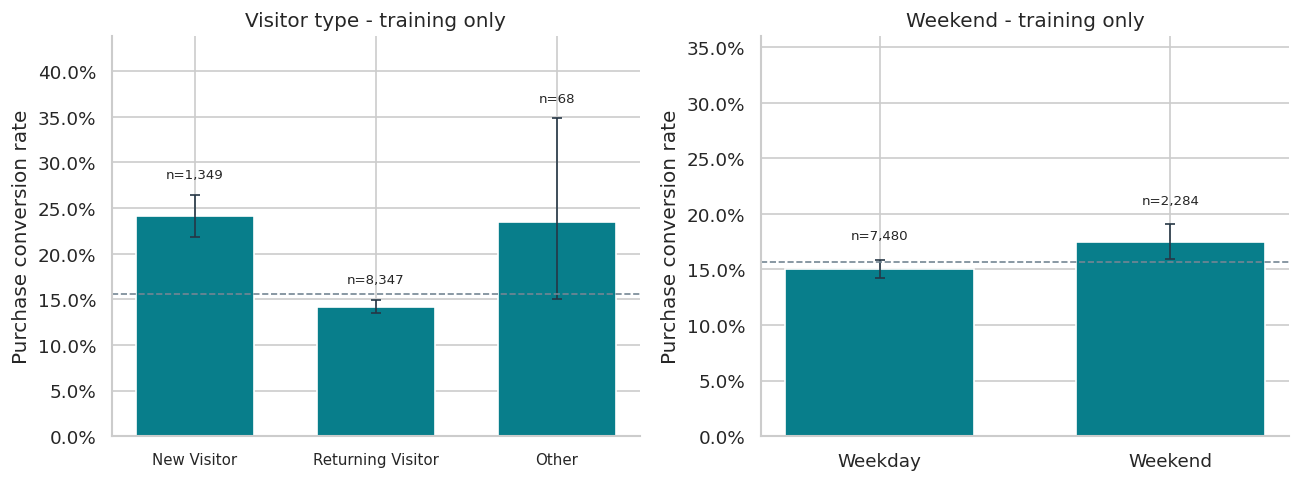

,sessions,purchases,conversion_rate,wilson_low,wilson_high
VisitorType,,,,,
New_Visitor,1349,325,0.2409,0.2189,0.2645
Returning_Visitor,8347,1185,0.1420,0.1346,0.1496
Other,68,16,0.2353,0.1503,0.3486


,sessions,purchases,conversion_rate,wilson_low,wilson_high
Weekend,,,,,
False,7480,1127,0.1507,0.1427,0.1590
True,2284,399,0.1747,0.1597,0.1908


In [8]:
def conversion_table(frame, col, order=None):
    t=frame.groupby(col, observed=True)['Revenue'].agg(sessions='size',purchases='sum')
    if order is not None: t=t.reindex(order)
    n=t['sessions'].fillna(0).astype(int)
    k=t['purchases'].fillna(0).astype(int)
    p=k.div(n.where(n>0))
    z=1.959963984540054
    d=1+z*z/n.where(n>0)
    center=(p+z*z/(2*n.where(n>0)))/d
    half=z*np.sqrt(p*(1-p)/n.where(n>0)+z*z/(4*n.where(n>0)**2))/d
    return pd.DataFrame({'sessions':n,'purchases':k,'conversion_rate':p,
                         'wilson_low':center-half,'wilson_high':center+half})

def conversion_plot(ax,t,title,count_labels=True):
    x=np.arange(len(t))
    p=t.conversion_rate.to_numpy(dtype=float)
    low=t.wilson_low.to_numpy(dtype=float); high=t.wilson_high.to_numpy(dtype=float)
    ax.bar(x,p,color=['#087e8b' if n>=50 else '#a1aab5' for n in t.sessions],width=.65)
    valid=np.isfinite(p)
    ax.errorbar(x[valid],p[valid],yerr=[p[valid]-low[valid],high[valid]-p[valid]],fmt='none',
                color='#263746',capsize=3,linewidth=1)
    if count_labels:
        for i,(n,hi) in enumerate(zip(t.sessions,high)):
            ax.text(i,hi+.018 if np.isfinite(hi) else .02,f'n={n:,}',ha='center',fontsize=8,rotation=0)
    ax.set_xticks(x, [str(v).replace('_',' ') for v in t.index])
    ax.axhline(y_train.mean(),ls='--',color='#748694',lw=1,label='Training purchase rate')
    ax.set(title=title,ylabel='Purchase conversion rate',ylim=(0,min(1,max(.36,np.nanmax(high)+.09))))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))

visitor=conversion_table(train,'VisitorType', ['New_Visitor','Returning_Visitor','Other'])
weekend=conversion_table(train,'Weekend',[False,True])
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
conversion_plot(axes[0],visitor,'Visitor type - training only')
conversion_plot(axes[1],weekend,'Weekend - training only')
axes[0].tick_params(axis='x',labelsize=9)
axes[1].set_xticks([0,1],['Weekday','Weekend'])
fig.tight_layout()
show_figure(fig,'04_visitor_weekend_conversion_train.png')
category_tables=[]
for col in NOMINAL_COLUMNS+['Weekend']:
    t=conversion_table(train,col).reset_index().rename(columns={col:'level'})
    t.insert(0,'feature',col)
    category_tables.append(t)
category_rates=pd.concat(category_tables,ignore_index=True)
save_table(category_rates,'07_category_conversion_train.csv')
display(visitor.round(4))
display(weekend.round(4))

**Takeaway.** New visitors convert at **24.09%** (n=1,349), compared with **14.20%** for returning visitors (n=8,347). The `Other` group has only 68 sessions and wider uncertainty. Keep visitor type as a predictor candidate; do not infer that a campaign aimed at new visitors would cause the same improvement. Weekend differences are descriptive and need model validation.

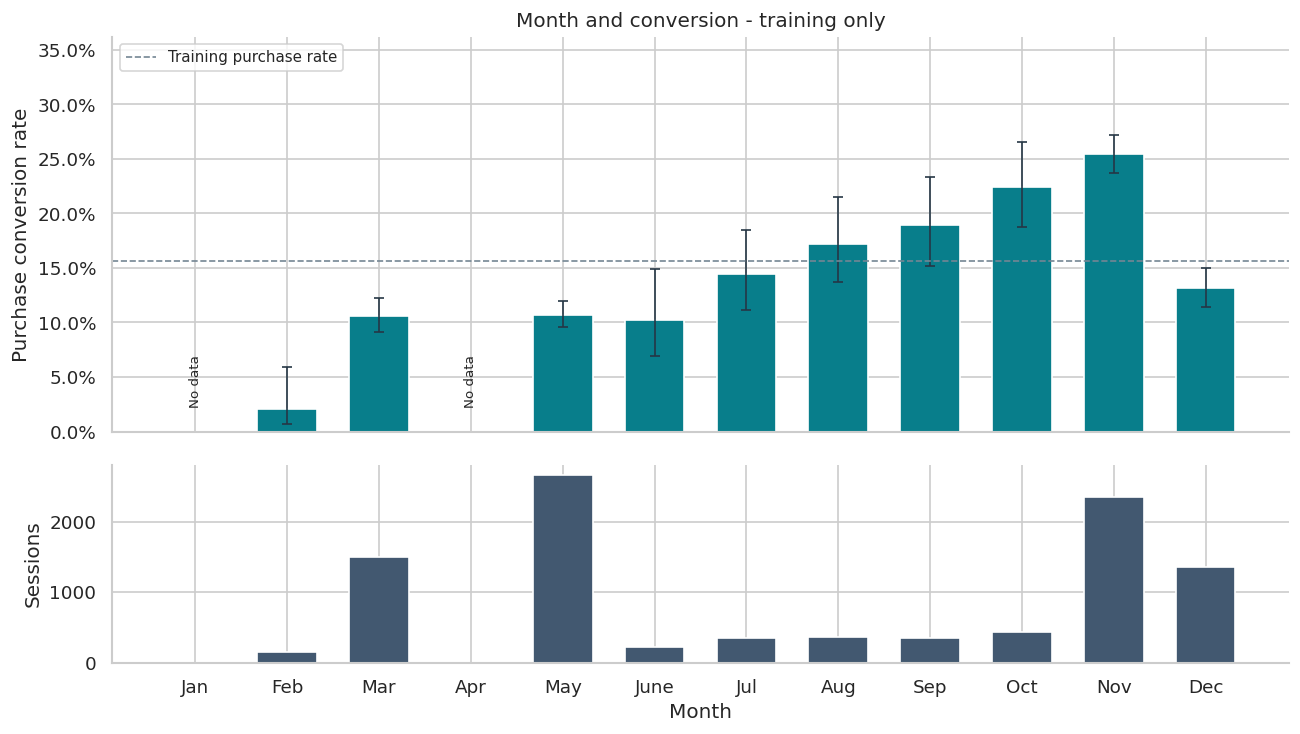

,sessions,purchases,conversion_rate,wilson_low,wilson_high
Month,,,,,
Jan,0,0,NaN,NaN,NaN
Feb,144,3,0.0208,0.0071,0.0595
Mar,1500,159,0.1060,0.0914,0.1226
Apr,0,0,NaN,NaN,NaN
May,2674,286,0.1070,0.0958,0.1192
June,225,23,0.1022,0.0691,0.1487
Jul,353,51,0.1445,0.1116,0.1850
Aug,360,62,0.1722,0.1367,0.2146
Sep,354,67,0.1893,0.1519,0.2333


In [9]:
monthly=conversion_table(train,'Month',MONTH_ORDER)
save_table(monthly.reset_index(names='Month'),'08_month_conversion_train.csv')
fig,axes=plt.subplots(2,1,figsize=(11,6.3),sharex=True,gridspec_kw={'height_ratios':[2,1]})
conversion_plot(axes[0],monthly,'Month and conversion - training only',count_labels=False)
axes[0].legend(loc='upper left',fontsize=9)
axes[1].bar(np.arange(12),monthly.sessions,color='#425870',width=.65)
axes[1].set(ylabel='Sessions',xlabel='Month')
axes[1].set_xticks(np.arange(12),MONTH_ORDER)
for i,n in enumerate(monthly.sessions):
    if n==0: axes[0].text(i,.025,'No data',ha='center',fontsize=8,rotation=90)
fig.tight_layout()
show_figure(fig,'05_month_conversion_volume_train.png')
display(monthly.round(4))

**Takeaway.** November has a **25.40%** training conversion rate (n=2,358), compared with **10.70%** in May (n=2,674). This supports categorical month encoding. The snapshot covers one year with no January or April rows; missing months are shown as unavailable rather than zero conversion, and the pattern cannot establish stable future seasonality.

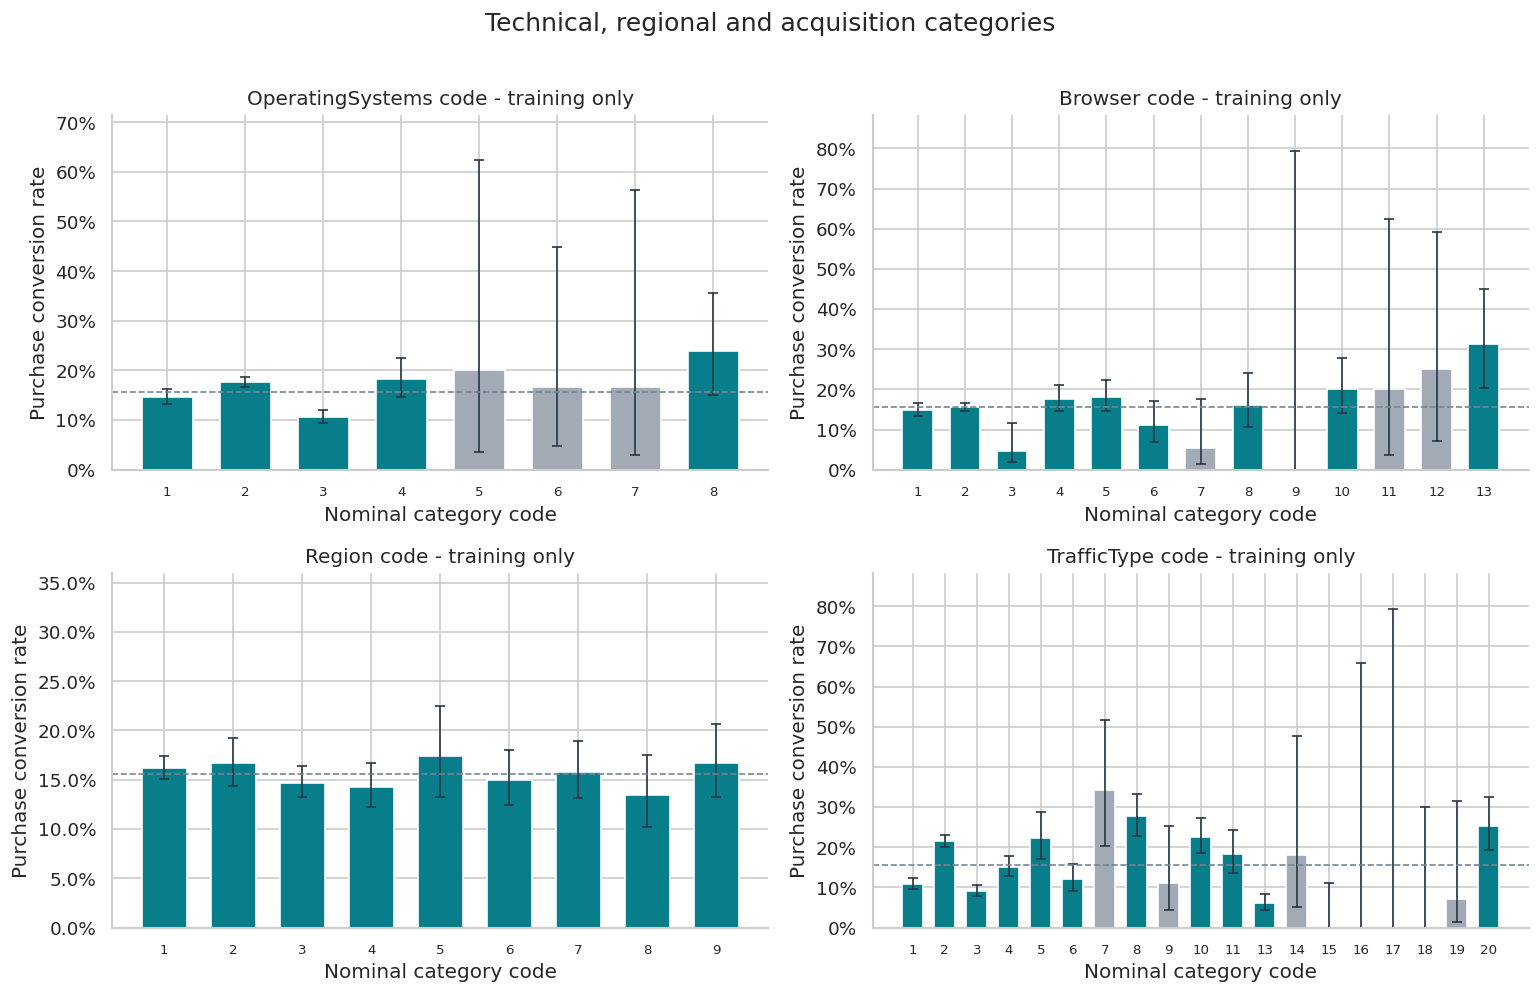

,feature,level,sessions,conversion_rate
14,OperatingSystems,5,5,0.200000
15,OperatingSystems,6,12,0.166667
16,OperatingSystems,7,6,0.166667
24,Browser,7,37,0.054054
26,Browser,9,1,0.000000
28,Browser,11,5,0.200000
29,Browser,12,8,0.250000
46,TrafficType,7,32,0.343750
48,TrafficType,9,36,0.111111
52,TrafficType,14,11,0.181818


In [10]:
fig,axes=plt.subplots(2,2,figsize=(13,8.2))
for ax,col in zip(axes.flat,['OperatingSystems','Browser','Region','TrafficType']):
    t=conversion_table(train,col)
    conversion_plot(ax,t,col+' code - training only',count_labels=False)
    ax.set_xlabel('Nominal category code')
    ax.tick_params(axis='x',labelsize=8)
fig.suptitle('Technical, regional and acquisition categories',fontsize=15,y=1.01)
fig.tight_layout()
show_figure(fig,'06_nominal_code_conversion_train.png')
rare=category_rates.loc[category_rates.sessions<50,['feature','level','sessions','conversion_rate']]
display(rare)

**Takeaway.** Category codes are labels, so a value of 10 does not mean twice as much traffic as 5. Gray bars mark levels with fewer than 50 training observations; their large uncertainty makes high conversion estimates unreliable. Keep names as codes because the file supplies no lookup to real browsers, regions, or acquisition channels. The pipeline handles unseen test categories without learning them from test data.

### 1.5 Correlations and candidate signals
Use Spearman correlation for skewed numeric features. This measures monotonic association rather than linear model importance. Categorical associations with the target are described with bias-corrected Cramer's V; rare cells remain a limitation.

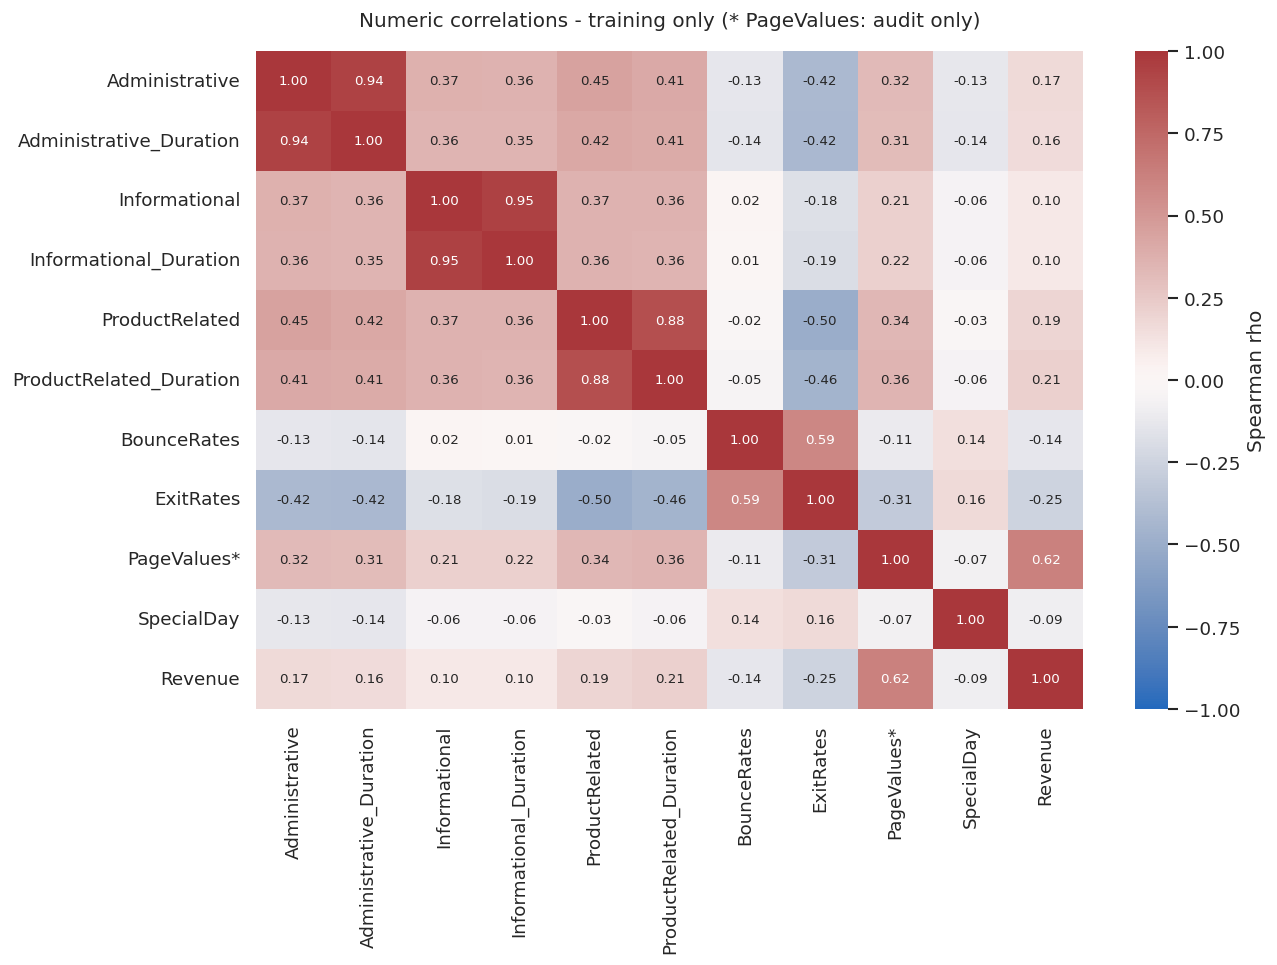

,feature,spearman_rho,default_input,abs_rho
8,PageValues,0.6240,False,0.6240
7,ExitRates,-0.2509,True,0.2509
5,ProductRelated_Duration,0.2127,True,0.2127
4,ProductRelated,0.1948,True,0.1948
0,Administrative,0.1665,True,0.1665
1,Administrative_Duration,0.1569,True,0.1569
6,BounceRates,-0.1403,True,0.1403
2,Informational,0.1013,True,0.1013
3,Informational_Duration,0.1000,True,0.1000
9,SpecialDay,-0.0900,True,0.0900


,feature,bias_corrected_cramers_v
0,Month,0.1725
4,TrafficType,0.1669
5,VisitorType,0.0947
1,OperatingSystems,0.0739
2,Browser,0.0427
6,Weekend,0.0261
3,Region,0.0000


In [11]:
spearman=train[numeric_original+['Revenue']].corr(method='spearman')
save_table(spearman.reset_index(names='feature'),'09_spearman_matrix_train.csv')
fig,ax=plt.subplots(figsize=(11,8.2))
labels=[c+'*' if c=='PageValues' else c for c in spearman.columns]
sns.heatmap(spearman,ax=ax,cmap='vlag',vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',
            annot_kws={'fontsize':8},xticklabels=labels,yticklabels=labels,cbar_kws={'label':'Spearman rho'})
ax.set_title('Numeric correlations - training only (* PageValues: audit only)',pad=15)
fig.tight_layout()
show_figure(fig,'07_spearman_heatmap_train.png')
associations=spearman['Revenue'].drop('Revenue').rename('spearman_rho').rename_axis('feature').reset_index()
associations['default_input']=associations.feature.ne('PageValues')
associations['abs_rho']=associations.spearman_rho.abs()
associations=associations.sort_values('abs_rho',ascending=False)
display(save_table(associations,'10_numeric_target_associations_train.csv').round(4))

def corrected_cramers_v(a,b):
    table=pd.crosstab(a,b)
    chi2=chi2_contingency(table,correction=False)[0]
    n=table.to_numpy().sum(); r,k=table.shape
    phi2=max(0,chi2/n-((k-1)*(r-1))/(n-1))
    r_adj=r-(r-1)**2/(n-1); k_adj=k-(k-1)**2/(n-1)
    return np.sqrt(phi2/min(k_adj-1,r_adj-1))

categorical_associations=pd.DataFrame([
    {'feature':c,'bias_corrected_cramers_v':corrected_cramers_v(train[c],y_train)}
    for c in NOMINAL_COLUMNS+['Weekend']]).sort_values('bias_corrected_cramers_v',ascending=False)
display(save_table(categorical_associations,'11_categorical_target_associations_train.csv').round(4))

**Takeaway.** Among default original numeric inputs, `ExitRates` has the strongest absolute training Spearman association with purchase (**rho = -0.2509**), followed by `ProductRelated_Duration` (**+0.2127**) and `ProductRelated` (**+0.1948**). This is an EDA ranking only. Strong correlations among page counts/durations and between bounce/exit metrics can create redundancy; their incremental value should be tested inside cross-validation.

**PageValues availability decision.** `PageValues` has a much stronger target association (**rho = +0.6240**), but UCI defines it in relation to transaction value. Its computation window is not documented sufficiently to establish that the value was available before the session purchase. We therefore exclude it from the default preparation pipeline. This is a conservative inference about leakage risk, not a claim that the field necessarily leaks. A later benchmark can include it only with explicit timing assumptions and an ablation comparison. Bounce/exit page metrics also need historical-window verification for deployment.

## 2. Feature engineering and automated preprocessing
Create interpretable row-level features to describe browsing depth, time intensity, product focus, and measurement gaps. These candidates add no external data and never use `Revenue`. Retain original features (except `PageValues`) so later cross-validation can compare original-only and augmented versions. Aggregates are algebraically related to original columns; regularization and ablation are needed before claiming improvement.

In [12]:
engineering_spec=pd.DataFrame([
 ['TotalPages','Administrative + Informational + ProductRelated','Overall browsing depth','log1p + standardize'],
 ['TotalDuration','Sum of the three page-type durations','Overall recorded engagement','log1p + standardize'],
 ['AvgTimePerPage','TotalDuration / TotalPages','Time intensity per tracked page','log1p + standardize'],
 ['AvgProductTime','ProductRelated_Duration / ProductRelated','Product research intensity','log1p + standardize'],
 ['AvgAdminTime','Administrative_Duration / Administrative','Administrative navigation intensity','log1p + standardize'],
 ['AvgInfoTime','Informational_Duration / Informational','Informational research intensity','log1p + standardize'],
 ['ProductPageShare','ProductRelated / TotalPages','Fraction of tracked pages related to products','standardize'],
 ['ProductTimeShare','ProductRelated_Duration / TotalDuration','Fraction of recorded time on products','standardize'],
 ['NoTrackedPages','1 if TotalPages = 0, else 0','Distinguishes undefined page-average denominators','0/1'],
 ['ZeroDurationSession','1 if TotalPages > 0 and TotalDuration = 0','Marks a session with no recorded dwell time','0/1'],
 ['HasInformational','1 if Informational > 0, else 0','Separates any informational browsing from none','0/1'],
 ['HasAdministrative','1 if Administrative > 0, else 0','Separates any administrative browsing from none','0/1'],
],columns=['feature','formula','business_rationale','transformation'])
display(save_table(engineering_spec,'12_feature_engineering_dictionary.csv'))

# This transformer has no learned population statistics; keep it inside the final pipeline anyway.
feature_engineer=SessionFeatureEngineer()
X_train_engineered=feature_engineer.fit_transform(X_train)
X_test_engineered=feature_engineer.transform(X_test)
assert 'PageValues' not in X_train_engineered
assert 'Revenue' not in X_train_engineered
engineered_names=engineering_spec.feature.tolist()
display(X_train_engineered[engineered_names].head().round(4))

engineered_associations=X_train_engineered[engineered_names].corrwith(y_train,method='spearman')
engineered_associations=engineered_associations.rename('spearman_rho').rename_axis('feature').reset_index()
save_table(engineered_associations,'13_engineered_associations_train.csv')
print('Engineered input table shape:', X_train_engineered.shape)

,feature,formula,business_rationale,transformation
0,TotalPages,Administrative + Informational + ProductRelated,Overall browsing depth,log1p + standardize
1,TotalDuration,Sum of the three page-type durations,Overall recorded engagement,log1p + standardize
2,AvgTimePerPage,TotalDuration / TotalPages,Time intensity per tracked page,log1p + standardize
3,AvgProductTime,ProductRelated_Duration / ProductRelated,Product research intensity,log1p + standardize
4,AvgAdminTime,Administrative_Duration / Administrative,Administrative navigation intensity,log1p + standardize
5,AvgInfoTime,Informational_Duration / Informational,Informational research intensity,log1p + standardize
6,ProductPageShare,ProductRelated / TotalPages,Fraction of tracked pages related to products,standardize
7,ProductTimeShare,ProductRelated_Duration / TotalDuration,Fraction of recorded time on products,standardize
8,NoTrackedPages,"1 if TotalPages = 0, else 0",Distinguishes undefined page-average denominators,0/1
9,ZeroDurationSession,1 if TotalPages > 0 and TotalDuration = 0,Marks a session with no recorded dwell time,0/1


,TotalPages,TotalDuration,AvgTimePerPage,AvgProductTime,AvgAdminTime,AvgInfoTime,ProductPageShare,ProductTimeShare,NoTrackedPages,ZeroDurationSession,HasInformational,HasAdministrative
source_row_id,,,,,,,,,,,,
7556,51,1256.0000,24.6275,25.0571,25.45,0.0,0.8235,0.8379,0,0,1,1
11924,30,901.2889,30.0430,30.0430,0.00,0.0,1.0000,1.0000,0,0,0,0
3306,13,421.1667,32.3974,32.3974,0.00,0.0,1.0000,1.0000,0,0,0,0
207,7,598.5000,85.5000,111.7000,20.00,0.0,0.7143,0.9332,0,0,0,1
4460,16,1599.2667,99.9542,99.9542,0.00,0.0,1.0000,1.0000,0,0,0,0


Engineered input table shape: (9764, 28)


**Zero-denominator rule.** A ratio with a zero denominator becomes 0; `NoTrackedPages` and `ZeroDurationSession` distinguish the corresponding measurement conditions. A zero time-per-page estimate means no recorded duration, not necessarily no real engagement. Missing source components propagate to a missing derived value and are imputed only inside the training-fitted pipeline.

**Transformation policy.** Apply `log1p(x)` to the six raw count/duration measures and six aggregate/average measures, then standardize. Standardize the five bounded numeric rates/shares without logging. Encode six nominal columns with one-hot encoding and `handle_unknown='ignore'`; keep five flags as 0/1. Although there are no missing values in this snapshot, median and most-frequent imputers are included for robustness. No outlier clipping or feature discretization is needed for this baseline. Month one-hot encoding preserves the observed November pattern without imposing smooth annual cyclicality on one year of data.

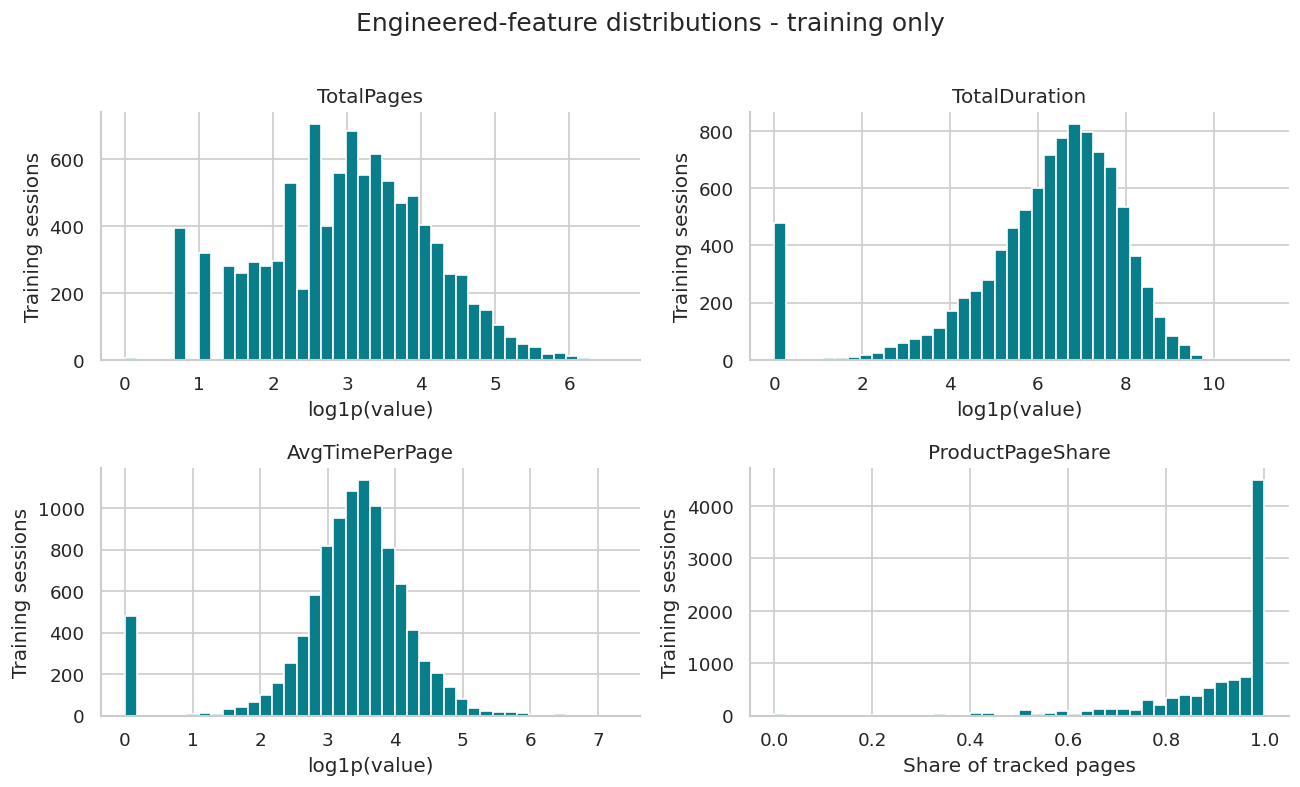

Prepared training matrix: (9764, 84)
Prepared test matrix: (2441, 84)
All prepared values are numeric and finite.


In [13]:
fig,axes=plt.subplots(2,2,figsize=(11,6.5))
for ax,col in zip(axes.flat,['TotalPages','TotalDuration','AvgTimePerPage','ProductPageShare']):
    vals=X_train_engineered[col]
    is_log=col!='ProductPageShare'
    ax.hist(np.log1p(vals) if is_log else vals,bins=40,color='#087e8b')
    ax.set(title=col,xlabel='log1p(value)' if is_log else 'Share of tracked pages',ylabel='Training sessions')
fig.suptitle('Engineered-feature distributions - training only',fontsize=15,y=1.01)
fig.tight_layout()
show_figure(fig,'08_engineered_distributions_train.png')

preprocessor=make_preprocessing_pipeline()
train_array=preprocessor.fit_transform(X_train,y_train)  # fit here, never on the test rows
test_array=preprocessor.transform(X_test)                # reuse training medians/scales/categories
feature_names=preprocessor.get_feature_names_out()
X_train_prepared=pd.DataFrame(train_array,columns=feature_names,index=X_train.index)
X_test_prepared=pd.DataFrame(test_array,columns=feature_names,index=X_test.index)
assert X_train_prepared.columns.equals(X_test_prepared.columns)
assert np.isfinite(X_train_prepared.to_numpy()).all() and np.isfinite(X_test_prepared.to_numpy()).all()
assert not any('PageValues' in c or 'Revenue' in c or 'source_row_id' in c for c in feature_names)
print('Prepared training matrix:',X_train_prepared.shape)
print('Prepared test matrix:',X_test_prepared.shape)
print('All prepared values are numeric and finite.')

# Verify StandardScaler learned exactly the log-transformed training statistics.
log_cols=BASE_LOG_COLUMNS+ENGINEERED_LOG_COLUMNS
scaler=preprocessor.named_steps['columns'].named_transformers_['log'].named_steps['scale']
np.testing.assert_allclose(scaler.mean_,np.log1p(X_train_engineered[log_cols]).mean(axis=0))
# clone() must produce a fresh, unfitted preprocessing object for future CV folds.
fresh_preprocessor=clone(preprocessor)
assert not hasattr(fresh_preprocessor.named_steps['features'],'feature_names_in_')

encoded_names=pd.DataFrame({'column_position':np.arange(len(feature_names)),'feature':feature_names})
save_table(encoded_names,'14_prepared_feature_names.csv')

**Prepared-data takeaway.** The matrices share the same training-derived feature schema. One-hot columns are learned from training categories, so their number is a result of the training split. A category appearing only in test data produces an all-zero vector for that categorical field; this is a documented limitation, handled without peeking at test categories. The engineered candidates are not yet proven to improve prediction.

## 3. Training/test split, exports, and handoff
Use an **80/20 stratified random split**, with `random_state=42`. Deduplication leaves **12,205** records. Training has **9,764 sessions** (8,238 non-purchases and 1,526 purchases). Test has **2,441 sessions** (2,059 non-purchases and 382 purchases). Purchase rates are **15.6288%** and **15.6493%**, respectively.

Random holdout estimates generalization to comparable sampled sessions; it does not estimate future-time performance under seasonal or marketing drift. Exact timestamps and repeated-user IDs would be needed for chronological or user-group evaluation. The supplied source describes different users, but the CSV cannot verify that.

### 3.1 Save reproducible data and the fixed-split preprocessor
The raw split files keep `PageValues` for audit, whereas the engineered and encoded modeling tables exclude it. `source_row_id` identifies original input rows and joins features with labels. It must be excluded from model inputs. The supplied notebook covers only the requested preparation steps; final evaluation remains reserved for later model selection.

In [14]:
for name,features,labels,engineered,prepared in [
    ('train',X_train,y_train,X_train_engineered,X_train_prepared),
    ('test',X_test,y_test,X_test_engineered,X_test_prepared)]:
    features.join(labels).sort_index().to_csv(PROCESSED / f'{name}_raw.csv')
    engineered.sort_index().to_csv(PROCESSED / f'X_{name}_engineered.csv')
    # Write the larger matrices completely before replacing the public CSV path.
    matrix_path=PROCESSED / f'X_{name}_prepared.csv'
    staging_path=matrix_path.with_suffix('.csv.tmp')
    prepared.sort_index().to_csv(staging_path,float_format='%.15g')
    staging_path.replace(matrix_path)
    labels.sort_index().to_csv(PROCESSED / f'y_{name}.csv')

joblib.dump(preprocessor,BASE / 'artifacts/fitted_preprocessor.joblib')
manifest=pd.concat([
    pd.DataFrame({'source_row_id':X_train.index,'partition':'train'}),
    pd.DataFrame({'source_row_id':X_test.index,'partition':'test'})]).sort_values('source_row_id')
manifest.to_csv(PROCESSED / 'split_manifest.csv',index=False)

# Check the exported join order rather than assuming independent files align.
for name in ['train','test']:
    exported_X=pd.read_csv(PROCESSED / f'X_{name}_prepared.csv',index_col='source_row_id')
    exported_y=pd.read_csv(PROCESSED / f'y_{name}.csv',index_col='source_row_id')
    assert exported_X.index.equals(exported_y.index)
    assert len(exported_X)==len(exported_y)
    assert len(exported_X)==(len(X_train) if name=='train' else len(X_test))

results={
    'source_sha256':source_hash,'random_state':RANDOM_STATE,'test_size':TEST_SIZE,
    'raw_sessions':len(raw),'raw_features':raw.shape[1]-1,'raw_purchase_count':int(raw.Revenue.sum()),
    'raw_purchase_rate':float(raw.Revenue.mean()),'missing_cells':int(raw.isna().sum().sum()),
    'exact_duplicates_removed':int(is_duplicate.sum()),'clean_sessions':len(clean),
    'train_sessions':len(y_train),'test_sessions':len(y_test),
    'train_purchases':int(y_train.sum()),'test_purchases':int(y_test.sum()),
    'train_conversion_rate':float(y_train.mean()),'test_conversion_rate':float(y_test.mean()),
    'engineered_features_added':len(engineered_names),'default_original_features':X.shape[1]-1,
    'engineered_columns':X_train_engineered.shape[1],'prepared_columns':len(feature_names),
    'excluded_default_features':['PageValues'],'versions':versions,
}
(BASE / 'artifacts/preparation_summary.json').write_text(json.dumps(results,indent=2),encoding='utf-8')
(BASE / 'requirements.txt').write_text('\n'.join([
    f'numpy=={np.__version__}',f'pandas=={pd.__version__}',f'scipy=={scipy.__version__}',
    f'scikit-learn=={sklearn.__version__}',f'matplotlib=={__import__("matplotlib").__version__}',
    f'seaborn=={sns.__version__}',f'joblib=={joblib.__version__}',
    '# To open this notebook, also install JupyterLab or use Google Colab.',
])+'\n',encoding='utf-8')
print(json.dumps(results,indent=2))

{
  "source_sha256": "b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9",
  "random_state": 42,
  "test_size": 0.2,
  "raw_sessions": 12330,
  "raw_features": 17,
  "raw_purchase_count": 1908,
  "raw_purchase_rate": 0.15474452554744525,
  "missing_cells": 0,
  "exact_duplicates_removed": 125,
  "clean_sessions": 12205,
  "train_sessions": 9764,
  "test_sessions": 2441,
  "train_purchases": 1526,
  "test_purchases": 382,
  "train_conversion_rate": 0.15628840639082342,
  "test_conversion_rate": 0.15649324047521507,
  "engineered_features_added": 12,
  "default_original_features": 16,
  "engineered_columns": 28,
  "prepared_columns": 84,
  "excluded_default_features": [
    "PageValues"
  ],
  "versions": {
    "Python": "3.12.14",
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "scipy": "1.17.0",
    "scikit-learn": "1.8.0",
    "matplotlib": "3.10.8",
    "seaborn": "0.13.2",
    "joblib": "1.5.3"
  }
}


### 3.2 Correct next step for model comparison
For cross-validation, start with the **raw training features** and instantiate a **fresh preprocessing pipeline** inside the model pipeline. This refits medians, scales and category encoding within each fold. Do not cross-validate the exported prepared training matrix, because its preprocessing has already seen the entire training partition. The prepared matrices and serialized preprocessor are for the one fixed train/test fit.

```python
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

model = Pipeline([
    ('preprocess', make_preprocessing_pipeline()),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced')),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Execute in the later modeling phase, using X_train and y_train only:
# cv_results = cross_validate(model, X_train, y_train, cv=cv,
#                            scoring=['average_precision', 'roc_auc', 'f1'])
```

The full INSY 674 rubric additionally requires several model families, N-fold mean/std comparisons, error analysis, a 3-5 model shortlist, hyperparameter tuning, an ensemble comparison, final test evaluation, a GitHub repository, and slides. Those are subsequent tasks; this notebook completes the requested data preparation scope.

### 3.3 What has been learned, and what remains uncertain

- More product browsing and lower exit-rate metrics are associated with purchase in the training sample. Visitor type and month also vary meaningfully across observed conversion rates.
- Associations are neither causal marketing effects nor validated predictive importance. Later evaluation should report held-out metrics and training-only permutation/ablation evidence before answering the research question definitively.
- Exact duplicates may represent legitimate repeated patterns; preserving raw rows and a removal log makes a grouped-duplicate sensitivity analysis possible.
- Full-session totals can include behavior occurring too late for intervention. To build a real-time system, collect pre-checkout event snapshots at a fixed decision point, cart/add-to-cart signals, exact timestamps, and historical-only page metrics. Split by time and by user when relevant.
- Additional useful data: cart and checkout stage at prediction time; prices, promotions, inventory and delivery fees; channel names and campaign costs; consented user/session identifiers; and intervention outcomes for estimating incremental conversion lift.
- One website/year and missing calendar months limit transfer to other merchants, future campaigns, and January/April. Sparse category levels make some segment rates uncertain.
- Targeting high-intent customers does not guarantee incremental marketing value: customers who would purchase anyway may not benefit from an offer. Use a randomized campaign or uplift study after validating the propensity model.

### Sources
1. Uploaded `online_shoppers_intention.csv`: all computed numbers, charts and splits.
2. Uploaded `INSY_674_Final_Project_Rubric (1).pdf`, pp. 1-4: exploration and preparation requirements; later modeling and submission requirements.
3. Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [Dataset and variable definitions](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). DOI: [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q). CC BY 4.0. Accessed 2026-10-26. Definitions are paraphrased; the leakage policy is this project's conservative inference.